# 购物篮关联规则与商品相似度

**业务问题：** 哪些商品在购物篮内共同出现？高 lift 规则和相似商品如何解释？

> 本项目使用仓库内的合成教学数据，不代表真实企业业绩。笔记本复用同目录分析模块，确保脚本、结果表与图表口径一致。请使用 Python 3.11 并从仓库内部启动 Jupyter。

## 1. 读取数据

根据当前目录向上定位仓库，不在 notebook 中依赖 `__file__`，也不硬编码电脑路径。

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

# Works when Jupyter starts at the repo root, project directory or notebook directory.
start = Path.cwd().resolve()
root = next((p for p in (start, *start.parents)
             if (p / 'projects' / 'product-recommendation-analysis' / 'scripts' / 'analyze.py').is_file()), None)
if root is None:
    raise FileNotFoundError('请在本仓库内启动 Jupyter，或先切换到仓库根目录。')
project_dir = root / 'projects' / 'product-recommendation-analysis'
module_path = project_dir / 'scripts' / 'analyze.py'
spec = importlib.util.spec_from_file_location('product_recommendation_analysis', module_path)
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
df = analysis.load_data()
assert not df.empty
print('Input rows:', len(df))
display(df.head())


Input rows: 35


,transaction_id,customer_id,product_id,product_name,category,price
0,T001,C001,P002,Phone Case,Accessories,99.0
1,T001,C001,P003,Screen Protector,Accessories,29.0
2,T001,C001,P001,Smartphone,Electronics,2999.0
3,T002,C002,P004,Laptop,Electronics,5999.0
4,T002,C002,P005,Laptop Bag,Accessories,199.0


## 2. 数据质量检查

报告缺失与整行重复。重复事件可能是真实行为，不应未经业务判断直接删除。分析模块进一步校验必要字段和数值范围。

In [2]:
display(df.isna().sum().to_frame('missing_count'))
print('Exact duplicate rows:', int(df.duplicated().sum()))

,missing_count
transaction_id,0
customer_id,0
product_id,0
product_name,0
category,0
price,0


Exact duplicate rows: 0


## 3. 指标定义与独立复算

Support 是项集出现的购物篮占比；Confidence(A→B) = support(A∪B) / support(A)；Lift = confidence / support(B)。演示代码穷举小购物篮子集，不冒称 Apriori；商品余弦相似度基于二值用户—商品矩阵，不等同于经过离线评估的推荐系统。

In [3]:
baskets = df.groupby('transaction_id')['product_name'].agg(lambda values: sorted(set(values)))
print('Baskets:', len(baskets))
print('Distinct product names:', df['product_name'].nunique())
display(baskets.to_frame('items').head())
display(baskets.map(len).value_counts().sort_index().to_frame('basket_count'))

Baskets: 15
Distinct product names: 11


,items
transaction_id,
T001,"[Phone Case, Screen Protector, Smartphone]"
T002,"[Laptop, Laptop Bag, Wireless Mouse]"
T003,"[Phone Case, Smartphone]"
T004,"[Headphones, Phone Case]"
T005,"[Laptop, Laptop Bag]"


,basket_count
product_name,
2,10
3,5


## 4. 完整分析结果

下面调用可复用的 `analyze(df)`，展示结果表；业务口径详见相邻项目说明和脚本。

In [4]:
results = analysis.analyze(df)
assert isinstance(results, dict) and results
for name, table in results.items():
    print(f'--- {name} ---')
    with pd.option_context('display.max_rows', 50, 'display.max_columns', 20):
        display(table)

--- overview ---


,input_rows,transactions,customers,analytical_items_by_name,catalog_product_ids
0,35,15,15,11,12


--- frequent_itemsets ---


,itemset,support_count,support
0,"(Phone Case,)",7,0.466667
1,"(Phone Case, Smartphone)",5,0.333333
2,"(Smartphone,)",5,0.333333
3,"(Laptop,)",4,0.266667
4,"(Headphones,)",3,0.200000
5,"(Laptop, Laptop Bag)",3,0.200000
6,"(Laptop, Wireless Mouse)",3,0.200000
7,"(Laptop Bag,)",3,0.200000
8,"(Tablet,)",3,0.200000
9,"(Wireless Mouse,)",3,0.200000


--- association_rules ---


...

product_name,Headphones,Laptop,Laptop Bag,Phone Case,Screen Protector,Smartphone,Stylus Pen,Tablet,Tablet Case,Wireless Earbuds,Wireless Mouse
product_name,,,,,,,,,,,
Headphones,1.000000,0.000000,0.000000,0.436436,0.000000,0.000000,0.00000,0.000000,0.000000,0.408248,0.000000
Laptop,0.000000,1.000000,0.866025,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.866025
Laptop Bag,0.000000,0.866025,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.666667
Phone Case,0.436436,0.000000,0.000000,1.000000,0.534522,0.845154,0.00000,0.000000,0.000000,0.267261,0.000000
Screen Protector,0.000000,0.000000,0.000000,0.534522,1.000000,0.632456,0.00000,0.000000,0.000000,0.000000,0.000000
Smartphone,0.000000,0.000000,0.000000,0.845154,0.632456,1.000000,0.00000,0.000000,0.000000,0.316228,0.000000
Stylus Pen,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.00000,0.577350,0.000000,0.000000,0.000000
Tablet,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.57735,1.000000,0.816497,0.000000,0.000000
Tablet Case,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.816497,1.000000,0.000000,0.000000


--- similar_items ---


,source_item,recommended_item,similarity
0,Headphones,Phone Case,0.436436
1,Headphones,Wireless Earbuds,0.408248
2,Laptop,Laptop Bag,0.866025
3,Laptop,Wireless Mouse,0.866025
4,Laptop Bag,Laptop,0.866025
5,Laptop Bag,Wireless Mouse,0.666667
6,Phone Case,Smartphone,0.845154
7,Phone Case,Screen Protector,0.534522
8,Phone Case,Headphones,0.436436
9,Screen Protector,Smartphone,0.632456


--- product_popularity ---


,product_name,transactions,support
0,Phone Case,7,0.466667
1,Smartphone,5,0.333333
2,Laptop,4,0.266667
3,Headphones,3,0.200000
4,Laptop Bag,3,0.200000
5,Tablet,3,0.200000
6,Wireless Mouse,3,0.200000
7,Screen Protector,2,0.133333
8,Tablet Case,2,0.133333
9,Wireless Earbuds,2,0.133333


## 5. 可视化

图表与脚本使用同一结果字典，不另写一套计算逻辑。

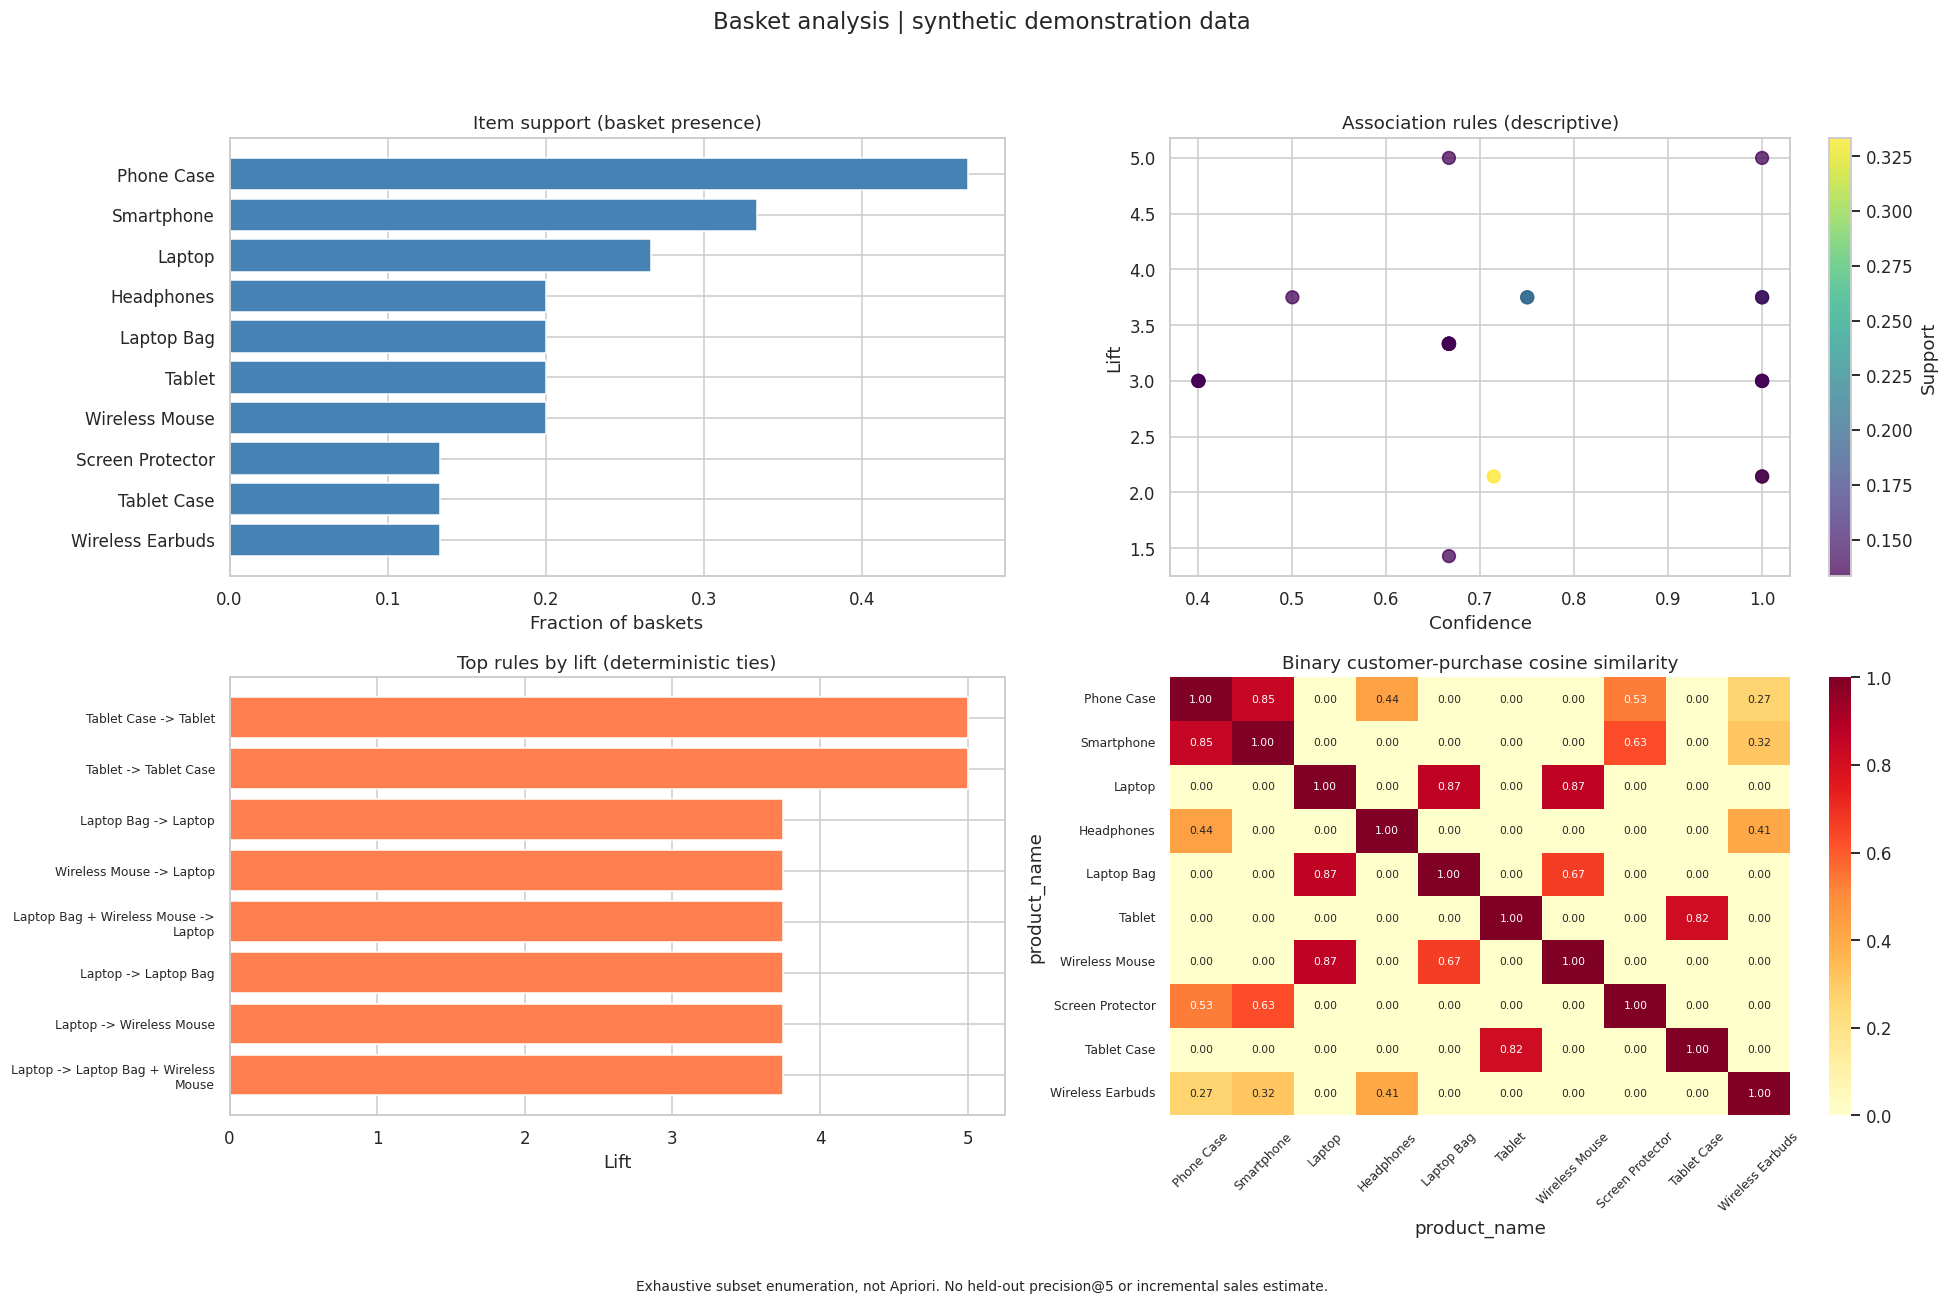

In [5]:
fig = analysis.plot_dashboard(results)
# Explicit PNG display also works with the headless Agg backend.
image = BytesIO()
fig.savefig(image, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image.getvalue()))
plt.close(fig)

## 6. 结论、建议与边界

样本有 15 个购物篮。Smartphone → Phone Case 的 confidence 为 1，lift 约为 2.14，但小样本的高 lift 不是销售提升保证。按 product_name 合并同名商品是演示口径；上线前必须清理商品主数据、核对同名不同 ID。没有训练/测试集划分或离线评估，不声称 precision@5、线上转化提升或已实现生产推荐。

**复现检查：** 从首个代码单元开始运行全部单元；仓库统一验证命令为 `python scripts/validate_portfolio.py`。生成笔记本和实际执行笔记本是两个不同步骤，执行结果以验证报告为准。